# Frequency analysis

The function [freq](../freq.rst) solves the eigenvalue problem
$(\boldsymbol{K} + \lambda^2 \boldsymbol{M}) \boldsymbol{u} = \boldsymbol{0}$,
where $\lambda^2 = -\omega_n^2$ and $\omega_n$ is the natural frequency in
rad/s. The returned `lambda2` are therefore negative for a stable structure,
and

```python
omega = np.sqrt(-lambda2)   # rad/s
f = omega/(2*np.pi)         # Hz
```

with `np.sqrt(-lambda2 + 0j)` when `lambda2` may be complex or positive,
e.g. beyond a flutter or a divergence load, see
[Follower loads and unsymmetric matrices](ex_follower_loads.ipynb).

This example calculates the natural frequencies of the clamped-free rod of
Petyt (2010), Example 3.3, compared with his results and with the exact
solution, shows the options of [freq](../freq.rst), and the frequencies of
a prestressed plate.

**Reference.** Petyt, M., Introduction to Finite Element Vibration
Analysis, 2nd ed., Cambridge University Press, 2010.
https://doi.org/10.1017/CBO9780511761195

In [1]:
%matplotlib inline
import os

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh
from scipy.sparse import csc_matrix, diags, lil_matrix, load_npz

from structsolve import freq, lb

## Clamped-free rod

The rod of length $L$, Young's modulus $E$, density $\rho$ and
cross-sectional area $A$, clamped at $x = 0$ and free at $x = L$, is
divided into $n$ elements of length $l = L/n$ with linear displacements,
whose stiffness and consistent inertia matrices are (Petyt 2010,
Example 3.3, p. 62)

$$
\boldsymbol{k}_e = \frac{E A}{l} \begin{bmatrix} 1 & -1 \\ -1 & 1
\end{bmatrix}, \qquad
\boldsymbol{m}_e = \frac{\rho A l}{6} \begin{bmatrix} 2 & 1 \\ 1 & 2
\end{bmatrix}
$$

The degree of freedom of the clamped end is removed. The function below is
the model of the test `test_freq_simple` of `tests/test_freq.py`, here with
$E = \rho = A = L = 1$:

In [2]:
def rod_clamped_free(num_elements, E=1., rho=1., A=1., L=1.):
    # K and M of the clamped-free rod, without the clamped dof
    n = num_elements + 1
    K = lil_matrix((n, n))
    M = lil_matrix((n, n))
    le = L/num_elements
    ke = E*A/le*np.array([[1., -1.], [-1., 1.]])
    me = rho*A*le/6*np.array([[2., 1.], [1., 2.]])
    for e in range(num_elements):
        K[e:e+2, e:e+2] += ke
        M[e:e+2, e:e+2] += me
    return csc_matrix(K[1:, 1:]), csc_matrix(M[1:, 1:])

### Two elements: Petyt's Example 3.3

With two elements and $\Lambda = \omega^2 \rho L^2/(24 E)$, the frequency
equation is $7 \Lambda^2 - 10 \Lambda + 1 = 0$, whose roots give
$\omega = (24 \Lambda)^{1/2} (E/(\rho L^2))^{1/2} = 1.610$ and $5.628$
(Petyt 2010, p. 63, Table 3.3, in units of $(E/(\rho L^2))^{1/2}$). The
dense solver of [freq](../freq.rst), `sparse_solver=False`, computes all
the eigenvalues of this model of two degrees of freedom:

In [3]:
K, M = rod_clamped_free(2)
lambda2, eigvecs = freq(K, M, silent=True, sparse_solver=False)
omega = np.sqrt(-lambda2.real)

Lambda = np.sort(np.roots([7., -10., 1.]))
omega_eq = np.sqrt(24*Lambda)
omega_table = np.array([1.610, 5.628])

print(f'{"mode":>4s} {"omega (freq)":>14s} {"roots of eq.":>14s} {"rel. diff.":>10s}'
      f' {"Table 3.3":>10s} {"rel. diff.":>10s}')
for i in range(2):
    print(f'{i+1:4d} {omega[i]:14.10f} {omega_eq[i]:14.10f}'
          f' {abs(omega[i] - omega_eq[i])/omega_eq[i]:10.1e}'
          f' {omega_table[i]:10.3f} {abs(omega[i] - omega_table[i])/omega_table[i]:10.1e}')

mode   omega (freq)   roots of eq. rel. diff.  Table 3.3 rel. diff.
   1   1.6114156823   1.6114156823    1.4e-16      1.610    8.8e-04
   2   5.6293031349   5.6293031349    3.2e-16      5.628    2.3e-04


The relative differences against Table 3.3 are those of its three
digits.

### Convergence to the exact frequencies

The exact natural frequencies and mode shapes of the rod are (Petyt 2010,
Eq. (3.26), p. 49)

$$
\omega_r = \frac{(2 r - 1) \pi}{2} \left(\frac{E}{\rho L^2}
\right)^{1/2}, \qquad \psi_r(x) = \sin \frac{(2 r - 1) \pi x}{2 L},
\qquad r = 1, 2, \ldots
$$

With 300 elements, the sparse solver computes the five lowest frequencies,
`num_eigvalues=5`:

In [4]:
n = 300
K, M = rod_clamped_free(n)
lambda2, eigvecs = freq(K, M, silent=True, num_eigvalues=5,
                        sparse_solver=True)
omega = np.sqrt(-lambda2.real)
r = np.arange(1, 6)
omega_exact = (2*r - 1)*np.pi/2

print(f'{"r":>2s} {"omega (freq)":>14s} {"Eq. (3.26)":>14s} {"rel. diff.":>10s}')
for i in range(5):
    print(f'{r[i]:2d} {omega[i]:14.8f} {omega_exact[i]:14.8f}'
          f' {(omega[i] - omega_exact[i])/omega_exact[i]:10.2e}')

 r   omega (freq)     Eq. (3.26) rel. diff.
 1     1.57079812     1.57079633   1.14e-06
 2     4.71243743     4.71238898   1.03e-05
 3     7.85420593     7.85398163   2.86e-05
 4    10.99618976    10.99557429   5.60e-05
 5    14.13847505    14.13716694   9.25e-05


The finite element frequencies are higher than the exact ones, and the
relative difference grows with the mode number. It decreases with the
number of elements, here for the first three frequencies:

   n  rel. diff. r=1  rel. diff. r=2  rel. diff. r=3
   4       6.437e-03       5.832e-02       1.535e-01
   8       1.607e-03       1.451e-02       4.048e-02
  16       4.016e-04       3.618e-03       1.007e-02
  32       1.004e-04       9.038e-04       2.512e-03
  64       2.510e-05       2.259e-04       6.276e-04
 128       6.275e-06       5.648e-05       1.569e-04
 256       1.569e-06       1.412e-05       3.922e-05


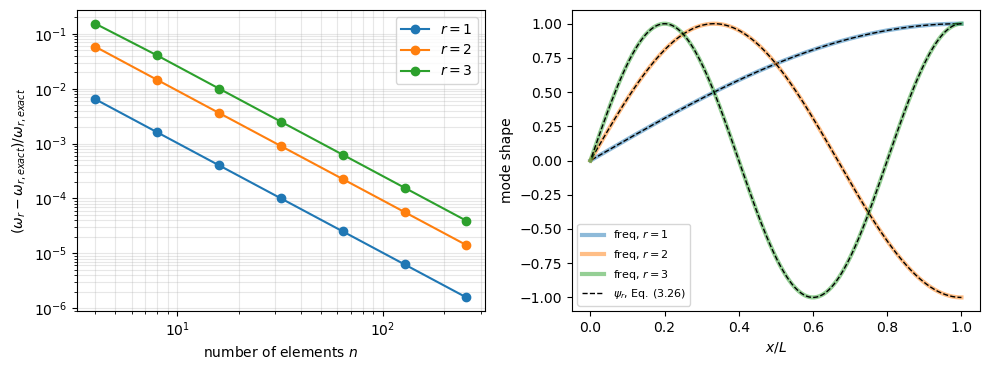

In [5]:
ns = [4, 8, 16, 32, 64, 128, 256]
errs = []
for n_el in ns:
    K_, M_ = rod_clamped_free(n_el)
    l2, _ = freq(K_, M_, silent=True, sparse_solver=False)
    w = np.sqrt(-l2.real)[:3]
    errs.append((w - omega_exact[:3])/omega_exact[:3])
errs = np.array(errs)

print(f'{"n":>4s}' + ''.join(f' {"rel. diff. r=" + str(i+1):>15s}' for i in range(3)))
for n_el, e in zip(ns, errs):
    print(f'{n_el:4d}' + ''.join(f' {ei:15.3e}' for ei in e))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for i in range(3):
    axes[0].loglog(ns, errs[:, i], 'o-', label=f'$r = {i+1}$')
axes[0].set_xlabel('number of elements $n$')
axes[0].set_ylabel(r'$(\omega_r - \omega_{r,exact})/\omega_{r,exact}$')
axes[0].grid(True, which='both', alpha=0.3)
axes[0].legend()

x = np.linspace(1./n, 1., n)
for i in range(3):
    u = eigvecs[:, i].real
    psi = np.sin((2*r[i] - 1)*np.pi*x/2)
    u = u*(u @ psi)/(u @ u)       # scaled to the exact mode shape
    axes[1].plot(np.concatenate(([0.], x)), np.concatenate(([0.], u)),
                 '-', lw=3, alpha=0.5, label=f'freq, $r = {i+1}$')
    axes[1].plot(x, psi, 'k--', lw=1)
axes[1].plot([], [], 'k--', lw=1, label=r'$\psi_r$, Eq. (3.26)')
axes[1].set_xlabel('$x/L$')
axes[1].set_ylabel('mode shape')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

The relative difference decreases by a factor of about four when the
number of elements doubles, as printed above, and the mode shapes of 300
elements, scaled by least squares, coincide with $\psi_r$.

## Options

- `symmetric`: `False`, the default, uses the general solvers, valid for
  unsymmetric matrices, and returns complex arrays. `True` uses the solvers
  of symmetric matrices, which require a positive definite `M`, and returns
  real arrays; `None` checks the symmetry of the matrices.
- Normalization: with `symmetric=True`, the eigenvectors are normalized with
  respect to `M`,
  $\boldsymbol{u}_i^\top \boldsymbol{M} \boldsymbol{u}_j = \delta_{ij}$.
  Otherwise the sparse solver returns eigenvectors normalized with respect to
  `M` and the dense solver eigenvectors with unit Euclidean norm, see
  [freq](../freq.rst); an application that needs a given normalization
  applies it to the returned eigenvectors.
- `sort`: `sort=True`, the default, sorts `lambda2` and the eigenvectors
  together by increasing natural frequency and removes the eigenpairs with
  $\omega_n \le 10^{-6}$ rad/s, e.g. rigid-body modes, such that fewer than
  `num_eigvalues` may be returned. `sort=False` keeps the order of the
  solver.
- `num_eigvalues`: the number of eigenvalues computed by the sparse solver,
  those closest to a negative shift, i.e. the lowest frequencies. See
  [Accuracy of the eigenvalue solutions](../eigen_accuracy.rst) for the
  verification of the results.

The model below, of the test `test_freq_sort` of `tests/test_freq.py`, has
twelve degrees of freedom of unit mass: ten springs to the ground, of
stiffnesses multiple of 100 in a random order, and a free-free pair of
degrees of freedom connected by a spring of stiffness 50, whose
$\omega_n^2$ are 0 (a rigid-body mode) and 100. The reference is the dense
solver `scipy.linalg.eigh`, independent of [freq](../freq.rst).

In [6]:
rng = np.random.RandomState(3)
n = 12
k = rng.permutation(np.arange(1, n + 1, dtype=float))*100
Kd = np.diag(k)
Kd[:2, :2] = 50.*np.array([[1., -1.], [-1., 1.]])
Md = np.eye(n)
K, M = csc_matrix(Kd), csc_matrix(Md)

w2_ref = eigh(Kd, Md, eigvals_only=True)
print('omega_n^2, scipy.linalg.eigh:', np.round(w2_ref, 8))

for sort in [False, True]:
    lambda2, eigvecs = freq(K, M, silent=True, num_eigvalues=6, sort=sort,
                            sparse_solver=True, symmetric=True)
    print(f'omega_n^2, freq with sort={sort}:', np.round(-lambda2, 8))

omega_n^2, scipy.linalg.eigh: [   0.  100.  100.  200.  300.  400.  700.  800.  900. 1000. 1100. 1200.]
omega_n^2, freq with sort=False: [  0. 100. 100. 200. 300. 400.]
omega_n^2, freq with sort=True: [100. 100. 200. 300. 400.]


With `sort=True`, the rigid-body mode is removed and the five lowest
non-null $\omega_n^2$ are returned in increasing order, with their
eigenvectors, normalized with respect to `M` with `symmetric=True`:

In [7]:
lambda2, eigvecs = freq(K, M, silent=True, num_eigvalues=6, sort=True,
                        sparse_solver=True, symmetric=True)
omega2 = -lambda2
ref = w2_ref[w2_ref > 1e-6][:omega2.size]
print(f'{"mode":>4s} {"omega_n^2 (freq)":>17s} {"eigh":>10s} {"rel. diff.":>10s}')
for i in range(omega2.size):
    print(f'{i+1:4d} {omega2[i]:17.10f} {ref[i]:10.4f}'
          f' {abs(omega2[i] - ref[i])/ref[i]:10.1e}')
print()
print('max |U^T M U - I| =', np.abs(eigvecs.T @ M @ eigvecs - np.eye(omega2.size)).max())

mode  omega_n^2 (freq)       eigh rel. diff.
   1    100.0000000000   100.0000    1.4e-16
   2    100.0000000000   100.0000    0.0e+00
   3    200.0000000000   200.0000    2.8e-16
   4    300.0000000000   300.0000    1.9e-16
   5    400.0000000000   400.0000    7.1e-16

max |U^T M U - I| = 4.440892098500626e-16


## Prestressed structures

The frequencies of a prestressed structure come from the stiffness matrix of
the prestressed state, e.g. $\boldsymbol{K} + \lambda \boldsymbol{K}_G$ with
the geometric stiffness matrix $\boldsymbol{K}_G$ of a reference load, see
[Linear buckling with a prestress](../lb_prestress.rst), or the tangent
stiffness matrix of a non-linear analysis. A compressive prestress reduces
the frequencies, and the lowest one vanishes at the buckling load.

### Column of two rigid bars

The column of Bathe (2014), Example 3.14, two rigid weightless bars of
length $L$ with the concentrated masses $m$ and $m/2$ and springs whose
stiffnesses are proportional to $k$, under the axial load $P$ (compression
negative), has the eigenvalue problem (Bathe 2014, Example 3.14, p. 98,
Eq. (c))

$$
\begin{bmatrix} 5k + \frac{2P}{L} & -\left(2k + \frac{P}{L}\right) \
-\left(2k + \frac{P}{L}\right) & 2k + \frac{P}{L} \end{bmatrix}
\begin{Bmatrix} U_1 \ U_2 \end{Bmatrix} = \omega^2
\begin{bmatrix} m & 0 \ 0 & \frac{m}{2} \end{bmatrix}
\begin{Bmatrix} U_1 \ U_2 \end{Bmatrix}
$$

i.e. the stiffness matrix
$\boldsymbol{K} + \lambda \boldsymbol{K}_G$ of the linear buckling
analysis of [Linear buckling analysis](ex_linear_buckling.ipynb), with
$\lambda = -P/L$, and the frequencies (p. 98)

$$
\omega_{1,2} = \left(\frac{9k}{2m} + \frac{2P}{mL} \mp
\sqrt{\frac{33k^2}{4m^2} + \frac{8Pk}{m^2L} + \frac{2P^2}{m^2L^2}}
\right)^{1/2}
$$

The lowest frequency vanishes at the critical load $P_{cr} = -2kL$
(p. 101). With $k = m = L = 1$:

**Reference.** Bathe, K.J., Finite Element Procedures, 2nd ed., K.J. Bathe,
Watertown, MA, 2014.

 P/(kL)    omega_1      Bathe rel. diff.    omega_2      Bathe rel. diff.
  -1.99   0.140713   0.140713    1.1e-14   1.010049   1.010049    2.2e-16
  -1.90   0.424717   0.424717    7.8e-16   1.104362   1.104362    2.0e-16
  -1.00   1.000000   1.000000    2.2e-16   2.000000   2.000000    0.0e+00
   0.00   1.275821   1.275821    1.7e-16   2.715195   2.715195    0.0e+00
   1.00   1.492648   1.492648    3.0e-16   3.282073   3.282073    0.0e+00
   5.00   2.141935   2.141935    2.1e-16   4.940862   4.940862    0.0e+00
  10.00   2.742640   2.742640    0.0e+00   6.440336   6.440336    0.0e+00


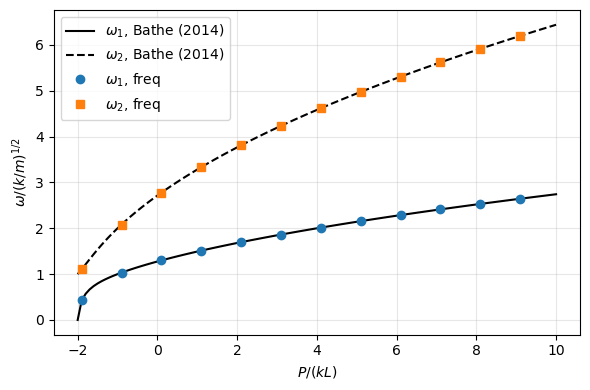

In [8]:
k = m = L = 1.
K = np.array([[5*k, -2*k], [-2*k, 2*k]])
KG = np.array([[-2., 1.], [1., -1.]])
M = np.diag([m, m/2])


def omega_bathe(P):
    s = np.sqrt(33*k**2/(4*m**2) + 8*P*k/(m**2*L) + 2*P**2/(m**2*L**2))
    a = 9*k/(2*m) + 2*P/(m*L)
    return np.sqrt(np.array([a - s, a + s]))


print(f'{"P/(kL)":>7s} {"omega_1":>10s} {"Bathe":>10s} {"rel. diff.":>10s}'
      f' {"omega_2":>10s} {"Bathe":>10s} {"rel. diff.":>10s}')
for P in [-1.99, -1.9, -1., 0., 1., 5., 10.]:
    lam = -P/L
    lambda2, _ = freq(csc_matrix(K + lam*KG), csc_matrix(M), silent=True,
                      sparse_solver=False, symmetric=True)
    w = np.sqrt(-lambda2)
    ref = omega_bathe(P)
    print(f'{P/(k*L):7.2f} {w[0]:10.6f} {ref[0]:10.6f} {abs(w[0] - ref[0])/ref[0]:10.1e}'
          f' {w[1]:10.6f} {ref[1]:10.6f} {abs(w[1] - ref[1])/ref[1]:10.1e}')

Ps = np.linspace(-2., 10., 121)
fig, ax = plt.subplots(figsize=(6, 4))
ref = np.array([omega_bathe(P) for P in Ps])
ax.plot(Ps, ref[:, 0]/np.sqrt(k/m), 'k-', label=r'$\omega_1$, Bathe (2014)')
ax.plot(Ps, ref[:, 1]/np.sqrt(k/m), 'k--', label=r'$\omega_2$, Bathe (2014)')
w = []
for P in Ps[1::10]:
    lambda2, _ = freq(csc_matrix(K - P/L*KG), csc_matrix(M), silent=True,
                      sparse_solver=False, symmetric=True)
    w.append(np.sqrt(-lambda2))
w = np.array(w)
ax.plot(Ps[1::10], w[:, 0], 'o', label=r'$\omega_1$, freq')
ax.plot(Ps[1::10], w[:, 1], 's', label=r'$\omega_2$, freq')
ax.set_xlabel('$P/(kL)$')
ax.set_ylabel(r'$\omega/(k/m)^{1/2}$')
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

### Plate

The matrices of a simply supported plate under uniaxial compression,
built with [panels](https://github.com/saullocastro/panels), are saved in
`tests/data`; the mass matrix here is diagonal, with random masses between
1 and 2, as in the test `test_freq_prestressed_plate` of
`tests/test_freq.py`. The critical load multiplier $\lambda_1$ comes from
[lb](../linear_buckling.rst), and the five lowest frequencies are
calculated for the prestress $\lambda = \alpha \lambda_1$, $0 \le \alpha < 1$.

The reference of each $\omega_n^2$ is the dense solver `scipy.linalg.eigh`.
The eigenvalues of this model span many orders of magnitude, and the
round-off of any solver in double precision limits the relative accuracy of
an eigenvalue $\omega_n^2$ to about
$\epsilon\, \omega_{max}^2/\omega_n^2$, with the machine epsilon $\epsilon$
and the highest eigenvalue $\omega_{max}^2$; this bound is printed with the
relative differences:

In [9]:
data = os.path.join('..', 'tests', 'data')
K = load_npz(os.path.join(data, 'plate_ssss_Nxx_K.npz')).tocsr()
KG = load_npz(os.path.join(data, 'plate_ssss_Nxx_KG.npz')).tocsr()
rng = np.random.RandomState(3)
M = diags(1. + rng.rand(K.shape[0])).tocsr()
print('degrees of freedom:', K.shape[0])

lambda_1 = lb(K, KG, silent=True, sparse_solver=False)[0][0]
print('critical load multiplier lambda_1 =', lambda_1)

eps = np.finfo(float).eps
alphas = [0., 0.25, 0.5, 0.75, 0.9, 0.99, 1 - 1e-4, 1 - 1e-6, 1 - 1e-7]
w2 = []
print()
print(f'{"alpha":>10s} {"omega_1^2 freq":>15s} {"omega_1^2 eigh":>15s}'
      f' {"rel. diff.":>10s} {"bound":>8s} {"max rel. diff. n=1..5":>22s}')
for alpha in alphas:
    KT = K + alpha*lambda_1*KG
    lambda2, eigvecs = freq(KT, M, silent=True, num_eigvalues=5,
                            symmetric=True)
    w2_freq = -lambda2
    w2_ref = eigh(KT.toarray(), M.toarray(), eigvals_only=True)
    bound = eps*w2_ref.max()/w2_ref[0]
    w2_ref = w2_ref[:5]
    rel = np.abs(w2_freq - w2_ref)/w2_ref
    w2.append(w2_freq)
    print(f'{alpha:10.7f} {w2_freq[0]:15.8e} {w2_ref[0]:15.8e} {rel[0]:10.1e}'
          f' {bound:8.1e} {rel.max():22.1e}')
w2 = np.array(w2)

degrees of freedom: 300
critical load multiplier lambda_1 = 157.5386247168361

     alpha  omega_1^2 freq  omega_1^2 eigh rel. diff.    bound  max rel. diff. n=1..5


 0.0000000  7.65886516e-07  7.65886512e-07    5.6e-09  1.3e-04                6.9e-09
 0.2500000  7.65530689e-07  7.65530687e-07    2.5e-09  1.3e-04                3.8e-09
 0.5000000  7.65173660e-07  7.65173656e-07    5.1e-09  1.3e-04                6.5e-09
 0.7500000  7.64814856e-07  7.64814855e-07    1.3e-09  1.3e-04                6.4e-09
 0.9000000  7.64598103e-07  7.64598102e-07    7.9e-10  1.3e-04                1.6e-09
 0.9900000  7.64467088e-07  7.64467097e-07    1.1e-08  1.3e-04                1.6e-08


 0.9999000  7.64452352e-07  7.64452349e-07    3.2e-09  1.3e-04                1.4e-08
 0.9999990  5.18398293e-08  5.18376057e-08    4.3e-05  1.9e-03                4.3e-05


 0.9999999  5.23515272e-09  5.23455597e-09    1.1e-04  1.9e-02                1.1e-04


The lowest frequencies of the plate hardly change with the prestress,
except the frequency of the buckling mode, which decreases to zero and
becomes the lowest close to $\lambda_1$. There, $\omega_1^2$ is
proportional to $1 - \alpha$: reducing $1 - \alpha$ ten times reduces
$\omega_1^2$ about ten times, within the round-off bound of the table:

omega_1^2(alpha = 1 - 1e-6)/omega_1^2(alpha = 1 - 1e-7) = 9.902257302235256 , rel. diff. to 10: 0.009774269776474397


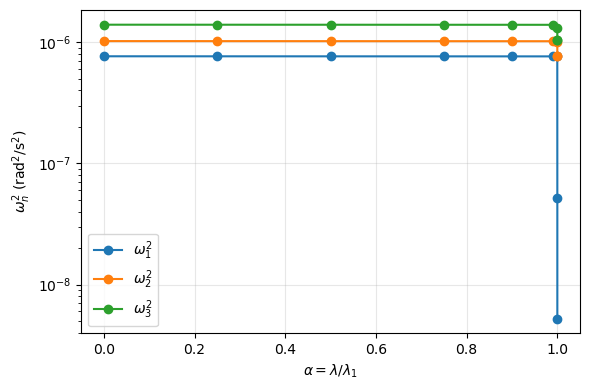

In [10]:
ratio = w2[-2, 0]/w2[-1, 0]
print('omega_1^2(alpha = 1 - 1e-6)/omega_1^2(alpha = 1 - 1e-7) =', ratio,
      ', rel. diff. to 10:', abs(ratio - 10)/10)

fig, ax = plt.subplots(figsize=(6, 4))
for i in range(3):
    ax.semilogy(alphas, w2[:, i], 'o-', label=r'$\omega_%d^2$' % (i + 1))
ax.set_xlabel(r'$\alpha = \lambda/\lambda_1$')
ax.set_ylabel(r'$\omega_n^2$ (rad$^2$/s$^2$)')
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()